# Lymph Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# load Merfish mouse brain 33 data
file_path = './lymph_data/2.h5ad'
file_path2 = './lymph_data/3.h5ad'

ad = sc.read(file_path)
ad_target = sc.read(file_path2)

In [3]:
ad.obs['original_clusters'].unique()

['Tumor', 'unknown', 'Plasma_IgG', 'Fibroblasts', 'CAF', ..., 'High_Endothelial_Venules', 'Tumor_Keratin_Pearl', 'CAM', 'Macrophages', 'Cortex_CCL21']
Length: 15
Categories (15, object): ['CAF', 'CAM', 'Cortex_CCL21', 'Cytotoxic_IFN_signaling', ..., 'T_cell', 'Tumor', 'Tumor_Keratin_Pearl', 'unknown']

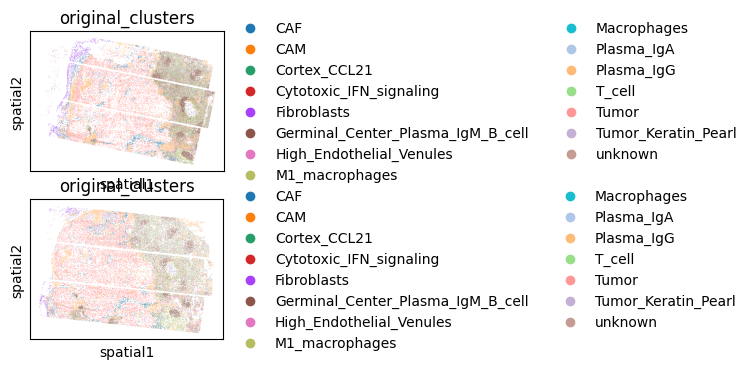

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(6, 4))

sc.pl.spatial(ad, color='original_clusters', spot_size=30, ax=axes[0], show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=30, ax=axes[1], show=False)
plt.show()

0 of 52405
10000 of 52405
20000 of 52405
30000 of 52405
40000 of 52405
50000 of 52405
52404 of 52405


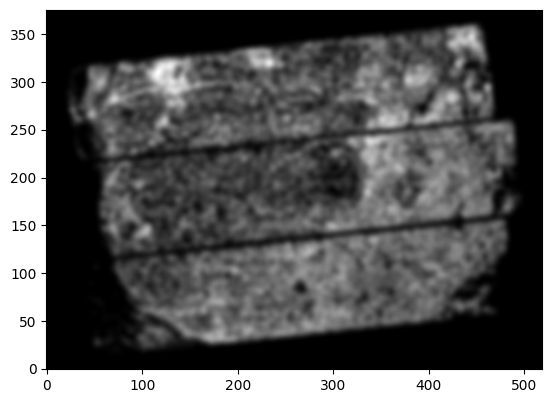

In [5]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 55400
10000 of 55400
20000 of 55400
30000 of 55400
40000 of 55400
50000 of 55400
55399 of 55400


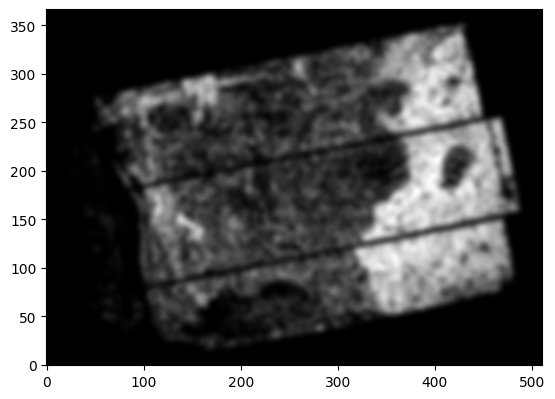

In [6]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

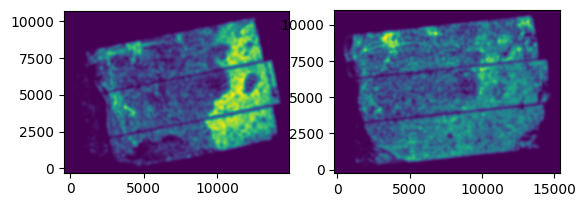

In [7]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: total: 3h 52min 17s
Wall time: 44min 54s


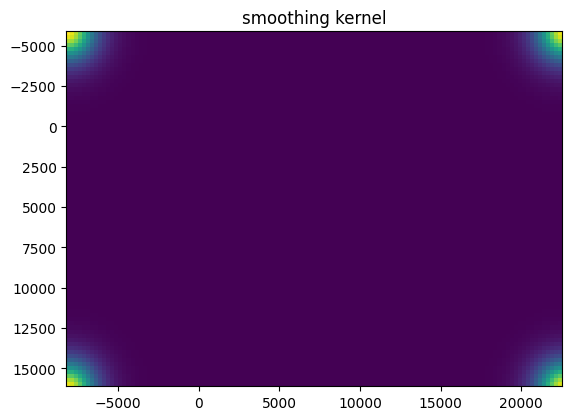

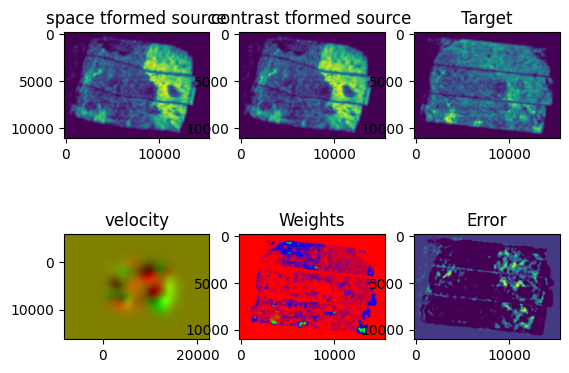

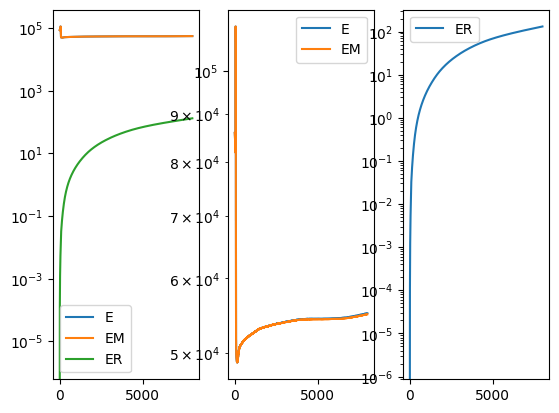

In [8]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            # 'niter':10000,
            # 'pointsI':pointsI,
            # 'pointsJ':pointsJ,
            # 'L':L,'T':T,
            'niter':8000,
            'device':device,
            'epV': 10,
            'sigmaA': 0.11, #standard deviation of artifact intensities
            'sigmaB': 0.1, #standard deviation of background intensities
            'sigmaM': 0.15, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [9]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']

In [10]:
pointsI = torch.tensor(np.stack([y, x], 1), device='cuda', dtype=torch.float64)

# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

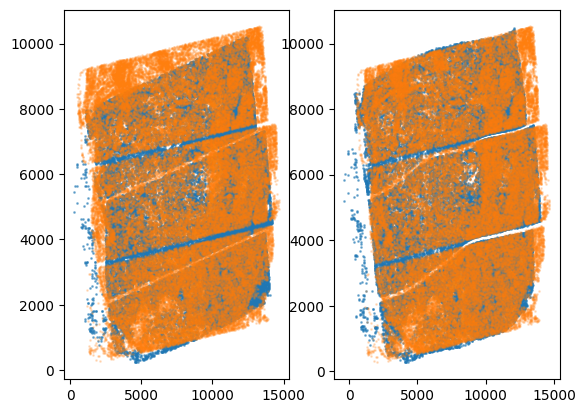

In [11]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.2, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.2, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

## LAA & ARI

In [12]:
from scipy.spatial import cKDTree
from sklearn.metrics import adjusted_rand_score


def find_nearest_points(f1, f2):
    """
    Find the nearest point in f2 for each point in f1 using batch processing.
    
    Args:
        f1 (numpy.ndarray): Array of shape (n_points_1, 2) representing points in f1.
        f2 (numpy.ndarray): Array of shape (n_points_2, 2) representing points in f2.
        batch_size (int): Number of points to process in each batch.
        
    """
    # Build a k-d tree for f2
    tree = cKDTree(f2)
    
    # Query the k-d tree for nearest neighbors of points in f1
    distances, nearest_indices = tree.query(f1)
        
    cnt = 0
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []

    for i in range(len(f1)):
        f1_cluster = ad_target.obs.iloc[i]['original_clusters']
        f2_cluster = ad.obs.iloc[nearest_indices[i]]['original_clusters']
        true_clusters_mapped_region.append(f1_cluster)
        mapped_clusters_mapped_region.append(f2_cluster)
        if f1_cluster == f2_cluster:
            cnt += 1 

    laa = cnt/len(f2)
    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
              
    return laa,ari


In [13]:
f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)

laa,ari = find_nearest_points(f1, f2)

print(laa)
print(ari)

0.31776173285198556
0.20271008846735486


## 3D

In [14]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,2_307,Tumor
1,2_309,unknown
2,2_446,Tumor
3,2_655,Tumor
4,2_656,Tumor


In [15]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 0
results1['slice'] = '2'
results1

,index,original_clusters,X,Y,Z,slice
0,2_307,Tumor,-343.385711,5192.792567,0,2
1,2_309,unknown,-337.818411,5822.743699,0,2
2,2_446,Tumor,-282.923151,6019.771882,0,2
3,2_655,Tumor,-105.946457,6618.385474,0,2
4,2_656,Tumor,-104.547074,6656.893067,0,2
...,...,...,...,...,...,...
55395,2_117838,M1_macrophages,13946.299487,4643.930669,0,2
55396,2_117855,M1_macrophages,13947.664864,4681.064646,0,2
55397,2_117863,M1_macrophages,13949.217261,4706.716207,0,2
55398,2_117887,unknown,13963.427376,4780.559784,0,2


In [16]:
results1.to_csv("2.csv", index=False)